# Multi-Agent Reinforcement Learning with Iterative Sequential Action Selection (MARLISA)

This notebook trains CityLearn's **MARLISA** controller and compares its deterministic final episode with `BasicRBC` and independent SAC.

The experiment keeps the common setup fixed: the same three buildings, 720-step local dataset, random seed, reward, SAC hyperparameters, exploration schedule, and KPI calculation. The main experimental change is MARLISA's demand estimation and information sharing between building policies.


## SAC versus MARLISA

Both controllers maintain one actor and two critics for every building. Independent SAC chooses each building's action from its local encoded observations. MARLISA adds:

1. a linear model that predicts each building's electricity demand after an action;
2. two coordination variables describing expected district demand and previously dispatched building capacity;
3. iterative action selection that passes coordination information through the building policies; and
4. PCA preprocessing after the initial exploration period.

The default run uses the same `IndependentSACReward` as the SAC notebook. This isolates the effect of coordination more clearly. Selecting CityLearn's `MARL` reward would define a different learning objective and should be reported as a separate experiment.

The installed CityLearn 3.0.2 implementation selects a policy using the coordination-iteration index during post-exploration action selection. With three buildings and two iterations, that bypasses a building policy. The project runner applies a narrow compatibility correction that selects `policy_net[building]`; all other MARLISA calculations remain unchanged. The correction is recorded in the run metadata.


In [1]:
from pathlib import Path
import json
import sys

import matplotlib.pyplot as plt
import pandas as pd

PROJECT_ROOT = Path.cwd().resolve()
if not (PROJECT_ROOT / 'src').is_dir():
    PROJECT_ROOT = PROJECT_ROOT.parent

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.run_marlisa import run_marlisa

SCHEMA = PROJECT_ROOT / 'notebooks' / 'data' / 'schema.json'
OUTPUT_DIRECTORY = PROJECT_ROOT / 'outputs' / 'marlisa'
print(f'Project root: {PROJECT_ROOT}')
print(f'Schema exists: {SCHEMA.is_file()}')


Project root: C:\Users\tanka\Dropbox\08-1 NUS Master in Computing AI specialization\CS5546 AI Planning and Decision Making\02Assignment
Schema exists: True


## Comparable configuration

The SAC settings below match `02_Independent_SAC.ipynb`. `TRAINING_EPISODES = 3` gives one initial exploration episode, one training episode, and one deterministic evaluation episode. It verifies the implementation but is too short for a final result.


In [ ]:
SEED = 42
TRAINING_EPISODES = 3
REWARD = 'independent_sac'

SAC_PARAMETERS = {
    'hidden_dimension': (256, 256),
    'discount': 0.99,
    'tau': 0.005,
    'alpha': 0.2,
    'learning_rate': 3e-4,
    'batch_size': 256,
    'replay_buffer_capacity': 100_000,
    'action_scaling_coefficient': 0.5,
    'reward_scaling': 5.0,
    'update_per_time_step': 1,
}

MARLISA_PARAMETERS = {
    'regression_buffer_capacity': 30_000, #--Stores up to 30,000 experience samples per building for training the electricity-demand prediction model.
    'start_regression_time_step': 2, #--Starts fitting the demand prediction model from time step 2.
    'regression_frequency': 2_500, #--Refits the demand prediction model every 2,500 time steps after its initial fitting.
    'information_sharing': True, #Allows agents to use shared coordination information, including predicted district demand and dispatched capacity.
    'pca_compression': 1.0, #Retains 100% of the encoded state dimensions during PCA, so there is effectively no dimensionality reduction
    'iterations': 2, #Performs two rounds of iterative sequential action selection at each time step.
}

pd.Series({
    'seed': SEED,
    'episodes': TRAINING_EPISODES,
    'reward': REWARD,
    **SAC_PARAMETERS,
    **MARLISA_PARAMETERS,
})


seed                                       42
episodes                                    3
reward                        independent_sac
hidden_dimension                   (256, 256)
discount                                 0.99
tau                                     0.005
alpha                                     0.2
learning_rate                          0.0003
batch_size                                256
replay_buffer_capacity                 100000
action_scaling_coefficient                0.5
reward_scaling                            5.0
update_per_time_step                        1
regression_buffer_capacity              30000
start_regression_time_step                  2
regression_frequency                     2500
information_sharing                      True
pca_compression                           1.0
iterations                                  2
dtype: object

MARLISA was configured with a 30,000-sample regression buffer, demand-model training beginning at time step 2 and recurring every 2,500 steps, information sharing enabled, full PCA dimensionality retained, and two rounds of iterative sequential action selection per time step.

## Train and evaluate MARLISA

This is slower than independent SAC because MARLISA also fits demand models, applies PCA, and performs iterative coordinated action selection. The final episode uses deterministic actor outputs and does not update the networks.


In [3]:
result = run_marlisa(
    schema=SCHEMA,
    output_directory=OUTPUT_DIRECTORY,
    episodes=TRAINING_EPISODES,
    random_seed=SEED,
    reward=REWARD,
    **SAC_PARAMETERS,
    **MARLISA_PARAMETERS,
)

env = result['env']
agent = result['agent']
print(f'Device: {agent.device}')
print(f'Building policies: {len(agent.policy_net)}')
print(f'Reward function: {type(env.reward_function).__name__}')
print(f'Information sharing: {agent.information_sharing}')
print(f'Demand estimators fitted: {agent.regression_flag}')
print(f'PCA fitted: {agent.pca_flag}')
print(f"Outputs: {result['output_directory']}")


Device: cpu
Building policies: 3
Reward function: IndependentSACReward
Information sharing: True
Demand estimators fitted: [2, 2, 2]
PCA fitted: [True, True, True]
Outputs: C:\Users\tanka\Dropbox\08-1 NUS Master in Computing AI specialization\CS5546 AI Planning and Decision Making\02Assignment\outputs\marlisa


## Episode rewards

Reward is useful for monitoring learning within one fixed reward definition. The final point is deterministic evaluation. Do not compare reward numbers from runs that use different reward functions.


,episode,phase,building,min,max,sum,mean
0,1,initial_exploration,Building_1,-7.713,0.0,-1087.782,-1.513
1,1,initial_exploration,Building_2,-10.483,0.0,-673.360,-0.937
2,1,initial_exploration,Building_3,-10.420,0.0,-930.556,-1.294
3,2,training,Building_1,-7.819,0.0,-511.552,-0.711
4,2,training,Building_2,-9.345,0.0,-312.801,-0.435
5,2,training,Building_3,-9.350,0.0,-553.690,-0.770
6,3,deterministic_evaluation,Building_1,-7.885,0.0,-430.406,-0.599
7,3,deterministic_evaluation,Building_2,-9.256,0.0,-250.395,-0.348
8,3,deterministic_evaluation,Building_3,-9.374,0.0,-485.194,-0.675


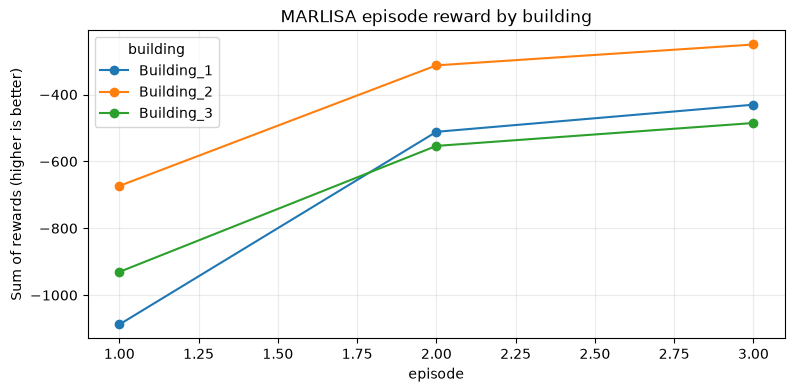

In [4]:
training_rewards = result['training_rewards']
display(training_rewards.round(3))

reward_plot = training_rewards.pivot(index='episode', columns='building', values='sum')
ax = reward_plot.plot(marker='o', figsize=(9, 4))
ax.set_title('MARLISA episode reward by building')
ax.set_ylabel('Sum of rewards (higher is better)')
ax.grid(alpha=0.25)
plt.show()


## MARLISA KPI results

The KPI table describes the final deterministic episode. CityLearn reports electricity, carbon, cost, peaks, ramping, and thermal discomfort independently of the reward used for learning. For normalized electricity KPIs, values below 1 improve on the corresponding no-control reference.


In [5]:
display(result['kpi_table'].round(3))
display(result['fairness'].round(3))


name,Building_1,Building_2,Building_3,District
cost_function,,,,
all_time_peak_average,NaN,NaN,NaN,0.859
annual_normalized_unserved_energy_total,0.027,0.015,0.019,0.020
carbon_emissions_total,0.410,0.401,0.514,0.442
cost_total,0.387,0.375,0.482,0.415
daily_one_minus_load_factor_average,NaN,NaN,NaN,1.274
daily_peak_average,NaN,NaN,NaN,0.713
discomfort_cold_delta_average,0.000,0.004,0.001,0.002
discomfort_cold_delta_maximum,0.124,0.581,0.232,0.312
discomfort_cold_delta_minimum,0.000,0.000,0.000,0.000


,average_discomfort,worst_discomfort,best_discomfort,discomfort_gap,worst_building
0,0.979,0.98,0.978,0.002,Building_3


## Compare RBC, independent SAC, and MARLISA

The runner automatically loads existing RBC and SAC KPI files. Run notebooks `01` and `02` first if a controller column is absent. RBC has no learning objective, so its behavior is unaffected by the environment reward. SAC and MARLISA use the same reward in this comparison.


,seed,time_steps,episodes,reward
controller,,,,
BasicRBC,42,720,1,not used for RBC actions
Independent SAC,42,720,3,independent_sac
MARLISA,42,720,3,independent_sac


,BasicRBC,Independent SAC,MARLISA,Carbon-aware MARLISA,Fair carbon-aware MARLISA
cost_function,,,,,
carbon_emissions_total,1.890,0.445,0.442,0.449,0.873
cost_total,1.843,0.418,0.415,0.422,0.856
electricity_consumption_total,1.900,0.452,0.448,0.456,0.877
daily_peak_average,1.329,0.715,0.713,0.716,0.910
ramping_average,0.924,0.889,0.885,0.887,1.098


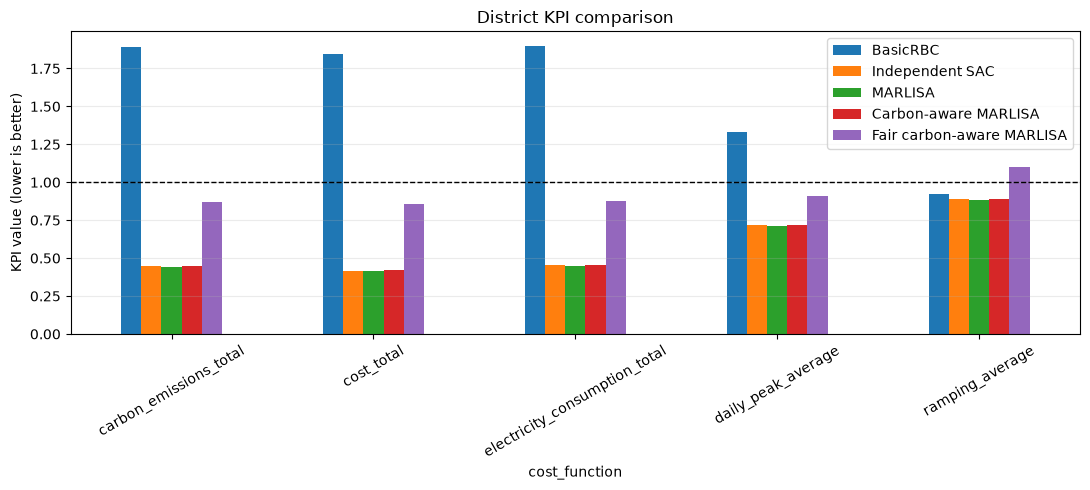

In [6]:
metadata_sources = {
    'BasicRBC': PROJECT_ROOT / 'outputs' / 'rbc' / 'metadata.json',
    'Independent SAC': PROJECT_ROOT / 'outputs' / 'independent_sac' / 'metadata.json',
}
contexts = []
for controller, path in metadata_sources.items():
    if path.is_file():
        metadata = json.loads(path.read_text(encoding='utf-8'))
        contexts.append({
            'controller': controller,
            'seed': metadata.get('random_seed'),
            'time_steps': metadata.get('episode_time_steps', metadata.get('time_steps')),
            'episodes': metadata.get('episodes', 1),
            'reward': metadata.get('reward_choice', 'not used for RBC actions'),
        })
contexts.append({
    'controller': 'MARLISA',
    'seed': result['metadata']['random_seed'],
    'time_steps': result['metadata']['episode_time_steps'],
    'episodes': result['metadata']['episodes'],
    'reward': result['metadata']['reward_choice'],
})
display(pd.DataFrame(contexts).set_index('controller'))

KEY_DISTRICT_KPIS = [
    'carbon_emissions_total',
    'cost_total',
    'electricity_consumption_total',
    'daily_peak_average',
    'ramping_average',
]

comparison = result['comparison']
available_kpis = [name for name in KEY_DISTRICT_KPIS if name in comparison.index]
display(comparison.loc[available_kpis].round(3))

ax = comparison.loc[available_kpis].plot.bar(figsize=(11, 5))
ax.axhline(1.0, color='black', linestyle='--', linewidth=1, label='No-control reference')
ax.set_ylabel('KPI value (lower is better)')
ax.set_title('District KPI comparison')
ax.tick_params(axis='x', rotation=30)
ax.grid(axis='y', alpha=0.25)
plt.tight_layout()
plt.show()


## Compare building-level discomfort fairness

The project defines operational fairness using the worst building's discomfort and the gap between the most and least uncomfortable buildings. Smaller values are better. This is fairness between simulated buildings, not demographic fairness.


In [7]:
controller_files = {
    'BasicRBC': PROJECT_ROOT / 'outputs' / 'rbc' / 'kpis.csv',
    'Independent SAC': PROJECT_ROOT / 'outputs' / 'independent_sac' / 'kpis.csv',
    'MARLISA': PROJECT_ROOT / 'outputs' / 'marlisa' / 'kpis.csv',
}

fairness_rows = []
for controller, path in controller_files.items():
    if not path.is_file():
        continue
    kpis = pd.read_csv(path)
    discomfort = kpis.loc[
        (kpis['level'] == 'building')
        & (kpis['cost_function'] == 'discomfort_proportion'),
        ['name', 'value'],
    ].dropna()
    if discomfort.empty:
        continue
    worst = discomfort.loc[discomfort['value'].idxmax()]
    fairness_rows.append({
        'controller': controller,
        'average_discomfort': discomfort['value'].mean(),
        'worst_discomfort': discomfort['value'].max(),
        'discomfort_gap': discomfort['value'].max() - discomfort['value'].min(),
        'worst_building': worst['name'],
    })

fairness_comparison = pd.DataFrame(fairness_rows).set_index('controller')
display(fairness_comparison.round(3))


,average_discomfort,worst_discomfort,discomfort_gap,worst_building
controller,,,,
BasicRBC,0.947,0.975,0.066,Building_1
Independent SAC,0.980,0.982,0.004,Building_1
MARLISA,0.979,0.980,0.002,Building_3


## Inspect coordinated actions

The action table contains the final deterministic episode. Look for differences between buildings and time periods. Coordination does not require identical actions; MARLISA uses district context to let each building choose an action suited to its own state.


,time_step,building,action,value
0,0,Building_1,dhw_storage,-0.357544
1,0,Building_1,electrical_storage,-0.454748
2,0,Building_1,cooling_device,0.022855
3,1,Building_1,dhw_storage,-0.378503
4,1,Building_1,electrical_storage,-0.447964
5,1,Building_1,cooling_device,0.025667
6,2,Building_1,dhw_storage,-0.348460
7,2,Building_1,electrical_storage,-0.444260
8,2,Building_1,cooling_device,0.027582
9,3,Building_1,dhw_storage,-0.346662


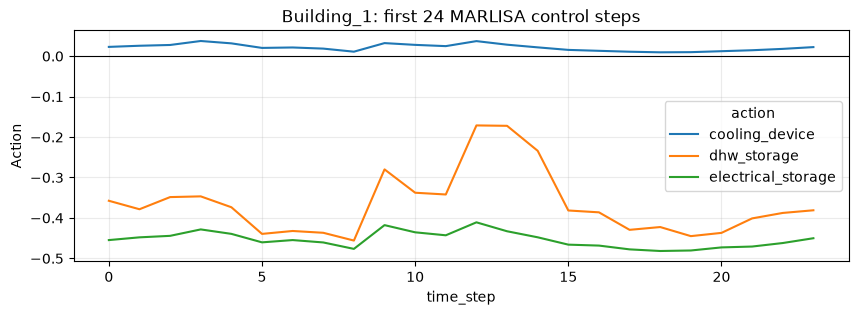

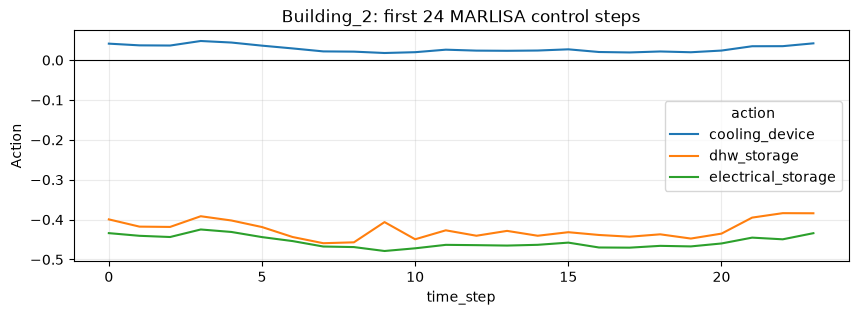

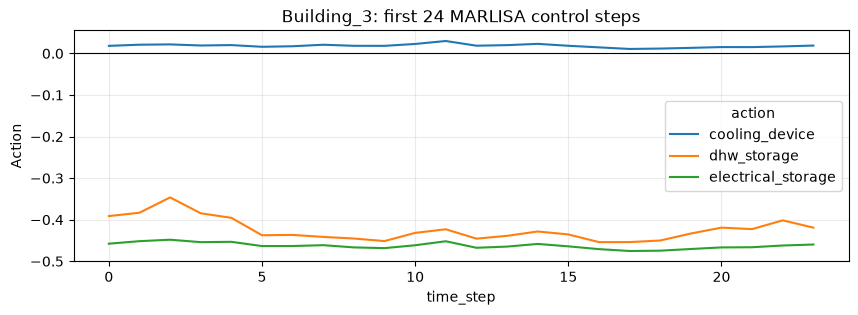

In [8]:
actions = result['actions']
display(actions.head(12))

first_day = actions.query('time_step < 24')
for building_name, building_actions in first_day.groupby('building'):
    action_plot = building_actions.pivot(index='time_step', columns='action', values='value')
    ax = action_plot.plot(figsize=(10, 3), title=f'{building_name}: first 24 MARLISA control steps')
    ax.axhline(0, color='black', linewidth=0.8)
    ax.set_ylabel('Action')
    ax.grid(alpha=0.25)
    plt.show()


## Interpretation and next experiment

A three-episode result only confirms that the pipeline operates. For the report:

1. define separate training and held-out evaluation periods;
2. train SAC and MARLISA for the same number of transitions;
3. run both learned controllers with the same set of random seeds;
4. report mean and variation for carbon, cost, peak demand, average discomfort, worst-building discomfort, and discomfort gap; and
5. change one design choice at a time when introducing the carbon-aware and fairness rewards.

Generated files are stored in `outputs/marlisa/`, including training rewards, final actions and rewards, KPIs, fairness summary, controller comparison, metadata, and a checkpoint.
